# Titanic: ответы на вопросы по данным

Ноутбук отвечает на вопросы о пассажирах Титаника: откуда они сели, как связаны каюта, пол и класс с выживанием, как распределены возраст и цена билета.

Для большинства шагов используется очищенный файл `train_clean.csv`, который создаёт `01_cleaning.ipynb`. Для возраста и цены билета берётся исходный `train-2.csv` (см. README): в очищенных данных пропуски возраста заполнены медианой, и это исказило бы форму распределения.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("train_clean.csv")

## Шаг 1. Порты посадки

Считаю, сколько пассажиров село в каждом порту, и строю столбчатую диаграмму. Заодно вывожу доли, чтобы увидеть масштаб.

Embarked
S    0.725028
C    0.188552
Q    0.086420
Name: proportion, dtype: float64


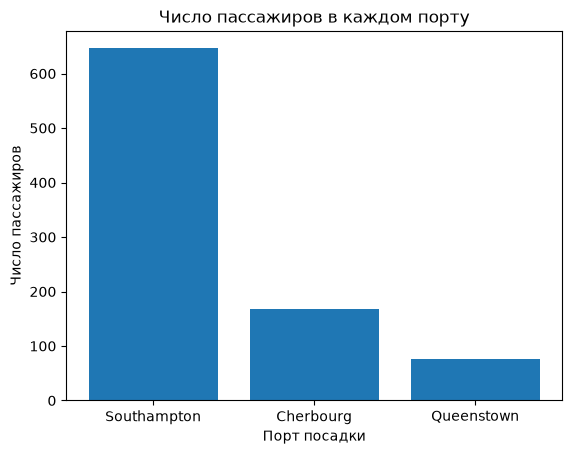

In [2]:
barr = df['Embarked'].value_counts()
fig, ax = plt.subplots()
ax.set_title('Число пассажиров в каждом порту')
ax.set_xlabel('Порт посадки')
ports = {'S': 'Southampton', 'C': 'Cherbourg', 'Q': 'Queenstown'}
labels = [ports[code] for code in barr.index]
ax.bar(labels, barr.values)
ax.set_ylabel('Число пассажиров')
shares = df['Embarked'].value_counts(normalize=True)
print(shares)

plt.show()

**Вывод:** большинство пассажиров (646 человек, около 72%) село в Саутгемптоне, в Шербуре сели 168, в Квинстауне 77.

## Шаг 2. Наличие каюты и выживание

Признак `HasCabin` появился при очистке (в исходных данных каюта указана лишь у части пассажиров). Смотрю, у какой доли пассажиров каюта известна, как это зависит от класса и как связано с выживанием.

In [3]:


print(df['HasCabin'].mean())
print(df.groupby('Pclass')['HasCabin'].mean())
print(df.groupby('HasCabin')['Survived'].mean())


0.22895622895622897
Pclass
1    0.814815
2    0.086957
3    0.024440
Name: HasCabin, dtype: float64
HasCabin
False    0.299854
True     0.666667
Name: Survived, dtype: float64


**Вывод:**
- Каюта указана у 23% пассажиров.
- По классам: 1 класс — 81%, 2 класс — 9%, 3 класс — 2%.
- Среди пассажиров с каютой выжили 67%, без каюты — 30%.

Связь между наличием каюты и выживанием нельзя считать причинной: каюта почти всегда указана у пассажиров 1 класса, а у них и шансы выше. Чтобы отделить влияние каюты от влияния класса, нужно сравнить выживаемость внутри одного класса.

## Шаг 3. Соотношение мужчин и женщин

Считаю число мужчин и женщин и показываю их доли на круговой диаграмме.

In [4]:
df['Sex'].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

Sex
male      0.647587
female    0.352413
Name: proportion, dtype: float64


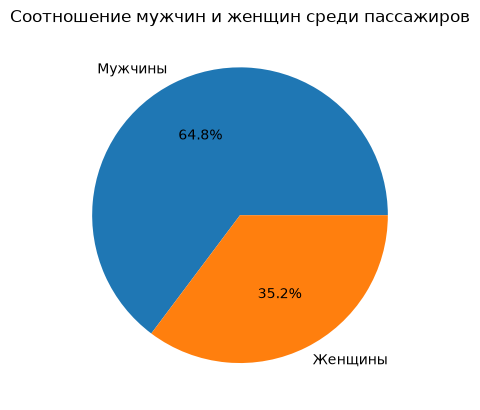

In [5]:
print(df['Sex'].value_counts(normalize=True))
bars = df['Sex'].value_counts()
pols = {'female': 'Женщины', 'male': 'Мужчины'}
labels1 = [pols[code] for code in bars.index]
fig, ax = plt.subplots()
ax.pie(bars,  labels = labels1,autopct='%1.1f%%')
ax.set_title('Cоотношение мужчин и женщин среди пассажиров')

plt.show()

**Вывод:** мужчин 577 (64,8%), женщин 314 (35,2%) — мужчин примерно в 1,8 раза больше.

## Шаг 4. Выживаемость по полу и классу

Сначала смотрю общую долю выживших и разбивки по полу, по классу и по обоим признакам сразу. Затем строю графики для каждой разбивки.

In [6]:
print(df['Survived'].mean())
print(df.groupby('Sex')['Survived'].mean())
print(df.groupby('Pclass')['Survived'].mean())
print(df.groupby(['Pclass','Sex'])['Survived'].mean())

0.3838383838383838
Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64
Pclass  Sex   
1       female    0.968085
        male      0.368852
2       female    0.921053
        male      0.157407
3       female    0.500000
        male      0.135447
Name: Survived, dtype: float64


### По полу

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64


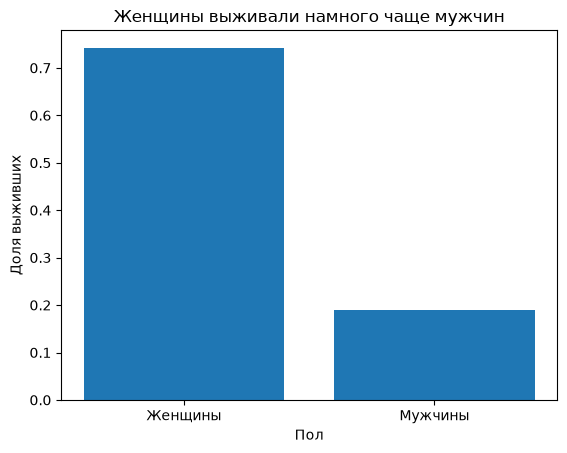

In [7]:
pols = {'female': 'Женщины', 'male': 'Мужчины'}

survival_by_sex = df.groupby('Sex')['Survived'].mean()
print(survival_by_sex)

labels = [pols[code] for code in survival_by_sex.index]

fig, ax = plt.subplots()
ax.bar(labels, survival_by_sex.values)
ax.set_title('Женщины выживали намного чаще мужчин')
ax.set_xlabel('Пол')
ax.set_ylabel('Доля выживших')
plt.show()

### По классу

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


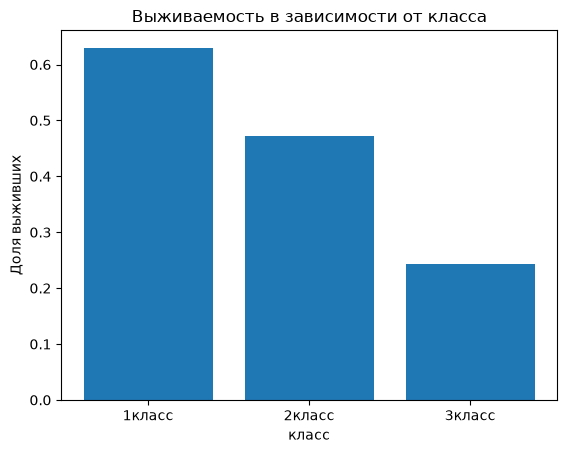

In [8]:
ports1 = {1: '1класс', 2 : '2класс', 3 : '3класс'}

survival_by_Pclass = df.groupby('Pclass')['Survived'].mean()
print(survival_by_Pclass)

labels2 = [ports1[code1] for code1 in survival_by_Pclass.index]

fig, ax = plt.subplots()
ax.bar(labels2, survival_by_Pclass.values)
ax.set_title('Выживаемость в зависимости от класса')
ax.set_xlabel('класс')
ax.set_ylabel('Доля выживших')
plt.show()

### По классу и полу вместе

Сравниваю выживаемость мужчин и женщин внутри каждого класса, чтобы проверить, что разница по полу не объясняется классом.

Sex       female      male
Pclass                    
1       0.968085  0.368852
2       0.921053  0.157407
3       0.500000  0.135447


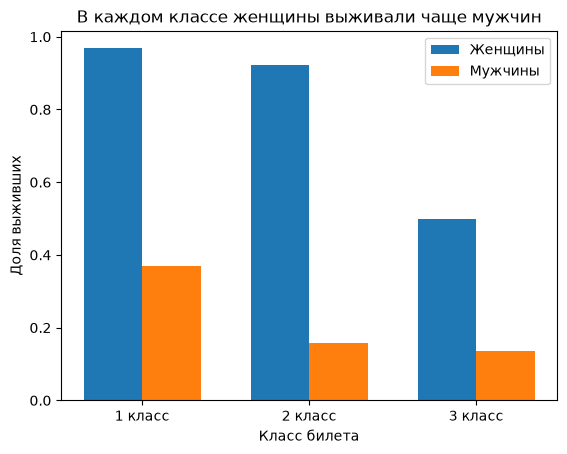

In [9]:

import numpy as np

h = df.groupby(['Pclass', 'Sex'])['Survived'].mean().unstack()
print(h)

x = np.arange(3)      # позиции групп: 0, 1, 2
width = 0.35          # ширина одного столбца

fig, ax = plt.subplots()
ax.bar(x - width/2, h['female'], width, label='Женщины')
ax.bar(x + width/2, h['male'], width, label='Мужчины')

ax.set_xticks(x)
ax.set_xticklabels(['1 класс', '2 класс', '3 класс'])
ax.set_title('В каждом классе женщины выживали чаще мужчин')
ax.set_xlabel('Класс билета')
ax.set_ylabel('Доля выживших')
ax.legend()
plt.show()

In [10]:
ax

<Axes: title={'center': 'В каждом классе женщины выживали чаще мужчин'}, xlabel='Класс билета', ylabel='Доля выживших'>

**Вывод:**
- Выжили 38% пассажиров.
- Женщины выживали намного чаще мужчин: 74% против 19%.
- Чем выше класс, тем выше выживаемость: 63% в 1 классе, 47% во 2 и 24% в 3.
- Разница по полу сохраняется в каждом классе: женщины 1 и 2 класса выжили почти все (97% и 92%), в 3 классе — 50%, а мужчины — от 37% в 1 классе до 14% в 3.

## Шаг 5. Распределение возраста

Беру возраст из исходного файла и отбрасываю пропуски: в очищенных данных они заполнены медианой, и гистограмма была бы искажена. Считаю среднее, медиану, минимум и максимум, затем строю гистограмму.

In [11]:
raw2 = pd.read_csv('train-2.csv')
age = raw2['Age'].dropna()
print(raw2['Age'].mean())
print(raw2['Age'].median())
print(raw2['Age'].min())
print(raw2['Age'].max())

29.69911764705882
28.0
0.42
80.0


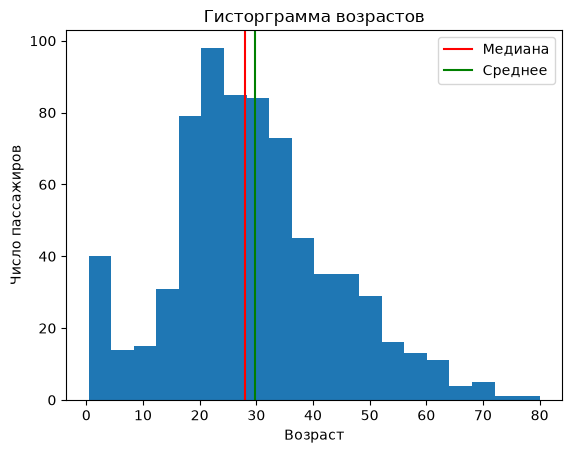

In [12]:
fig, ax = plt.subplots()
ax.hist(age, bins = 20)
ax.axvline(age.median(),color = 'red', label = 'Медиана')
ax.axvline(age.mean(),color = 'green',label = 'Среднее')
ax.legend()
ax.set_xlabel('Возраст')
ax.set_ylabel('Число пассажиров')
ax.set_title('Гисторграмма возрастов')
plt.show()

**Вывод:**
- Возраст известен у 714 из 891 пассажиров; среднее 29,7, медиана 28, диапазон от 0,42 до 80.
- Основная масса пассажиров — от 20 до 40 лет.
- Есть отдельный пик малышей (до 5 лет включительно — 44 человека), он заметно выше, чем в возрасте 6–10 лет (20 человек).
- Среднее чуть больше медианы: старшие пассажиры слегка тянут среднее вправо, распределение скошено вправо.

## Шаг 6. Цена билета

Использую исходный файл: пропусков в `Fare` нет, но цены нужны в том виде, в каком они были. Считаю среднее, медиану и крайние значения, строю гистограмму и боксплот, затем сравниваю цены по классам и смотрю на самые дорогие билеты (больше 500).

In [13]:
print(raw2['Fare'].mean())
print(raw2['Fare'].median())
print(raw2['Fare'].max())
print(raw2['Fare'].min())
print(raw2['Fare'].isnull().value_counts())


32.204207968574636
14.4542
512.3292
0.0
Fare
False    891
Name: count, dtype: int64


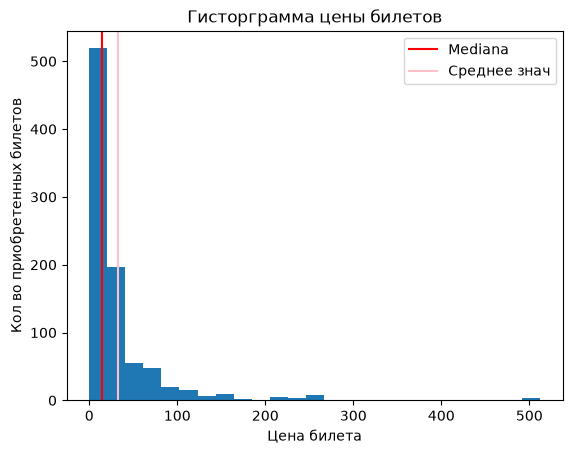

In [14]:
fig,ax = plt.subplots()
ax.hist(raw2['Fare'],bins = 25)
ax.set_xlabel('Цена билета')
ax.set_ylabel('Кол во приобретенных билетов')
ax.axvline(raw2['Fare'].median(), color = 'red',label  = 'Mediana')
ax.axvline(raw2['Fare'].mean(), color = 'pink',label  = 'Среднее знач')
ax.set_title('Гисторграмма цены билетов')
ax.legend()
plt.show()

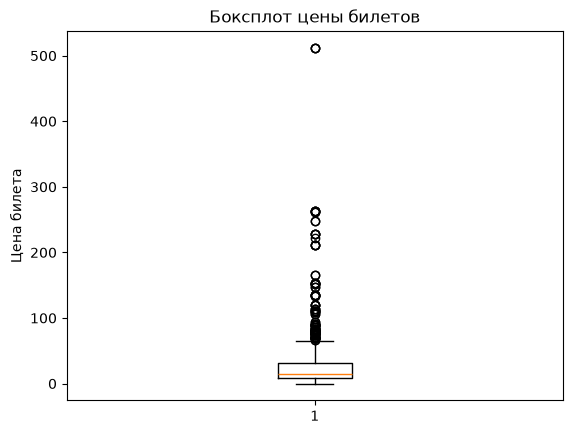

In [15]:
fig,ax = plt.subplots()
ax.set_ylabel('Цена билета')
ax.set_title('Боксплот цены билетов')
ax.boxplot(raw2['Fare'])
plt.show()

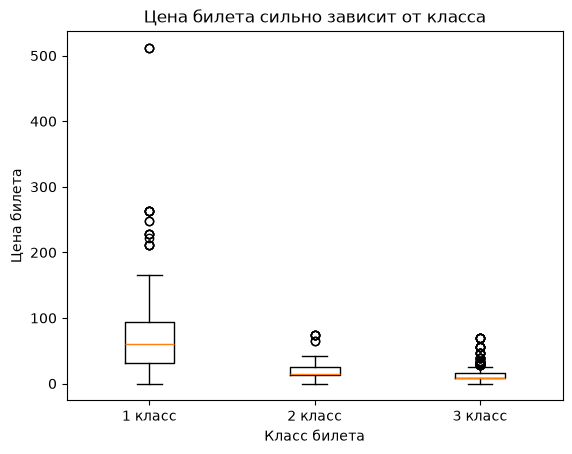

Pclass
1    60.2875
2    14.2500
3     8.0500
Name: Fare, dtype: float64


In [16]:
fares_by_class = [df[df['Pclass'] == c]['Fare'] for c in [1, 2, 3]]

fig, ax = plt.subplots()
ax.boxplot(fares_by_class, tick_labels=['1 класс', '2 класс', '3 класс'])
ax.set_title('Цена билета сильно зависит от класса')
ax.set_xlabel('Класс билета')
ax.set_ylabel('Цена билета')
plt.show()

print(df.groupby('Pclass')['Fare'].median())

In [17]:
df[df['Fare'] > 500]

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,HasCabin,FamilySize,IsAlone
258,1,1,"Ward, Miss. Anna",female,35.0,0,0,512.3292,C,False,1,True
679,1,1,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,0,1,512.3292,C,True,2,False
737,1,1,"Lesurer, Mr. Gustave J",male,35.0,0,0,512.3292,C,True,1,True


**Вывод:**
- Среднее (32,2) более чем вдвое больше медианы (14,5): небольшая часть очень дорогих билетов тянет среднее вверх.
- Распределение скошено вправо: большинство билетов дешёвые, но есть длинный хвост до 512.
- По классам медианы различаются: 1 класс — 60, 2 класс — 14, 3 класс — 8; дорогие билеты и выбросы почти все в первом классе.
- Три самых дорогих билета (512) — в 1 классе, все трое выжили, но выборка слишком мала для выводов.
- Типичную цену лучше описывает медиана: на неё не влияют единичные очень дорогие билеты.